# 🌡️ Aula 4: Projeto Prático de Coleta de Dados
## Disciplina: D1INT - Introdução à Ciência de Dados
## Professor: Danilo César Pereira
## Aluna: Ingrid dos Santos Cutrim
## Data: 09/11/2026

### 🎯 Objetivo:
Criar um dataset próprio coletando dados de múltiplas fontes da internet.

### 📋 Tema do Projeto:
**Clima nas 27 capitais brasileiras: o que explica mais a temperatura, a latitude ou a altitude?**

### 🎯 Justificativa:
O Brasil tem capitais quentes o ano todo e outras bem mais frias, mesmo estando em regiões vizinhas.
A explicação mais comum é "quanto mais ao sul, mais frio", mas cidades como Brasília e Curitiba sugerem
que a altitude também pesa. Quero montar um dataset próprio, com dados reais dos últimos 30 dias,
para comparar as capitais e verificar qual dos dois fatores está mais associado à temperatura.

### 🌐 Fontes de Dados:
1. **API de Localidades do IBGE**: https://servicodados.ibge.gov.br/api/v1/localidades/estados (estado e região de cada UF). Se ela não responder, o código usa a **BrasilAPI** (https://brasilapi.com.br/api/ibge/uf/v1), que repassa os mesmos dados do IBGE
2. **Open-Meteo Geocoding API**: https://geocoding-api.open-meteo.com/v1/search (latitude, longitude, altitude e população)
3. **Open-Meteo Weather Forecast API**: https://api.open-meteo.com/v1/forecast (temperatura, chuva e umidade diárias dos últimos 30 dias)

### 📊 Dados Coletados:
- Total de registros: 27 capitais no dataset final (+ cerca de 810 registros diários no dataset auxiliar)
- Colunas: ver o dicionário de dados no final do notebook
- Período: últimos 30 dias antes da data da coleta

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

## 🗺️ Plano de coleta (feito antes de programar)

| Pergunta | Resposta |
|---|---|
| **Qual pergunta quero responder?** | A temperatura média das capitais acompanha mais a latitude (distância do Equador) ou a altitude? |
| **Quais dados preciso?** | Região, coordenadas, altitude, temperatura (média, máxima e mínima), chuva e umidade |
| **Onde estão?** | IBGE (divisão territorial) e Open-Meteo (geografia e clima) |
| **Método** | Apenas **APIs REST** (JSON). Como existem APIs públicas, não foi preciso usar scraping ("se tem API, use API") |
| **Volume** | 27 capitais × 30 dias ≈ 810 registros diários, resumidos em 27 linhas |
| **Ética / limites** | APIs gratuitas e abertas, sem dados pessoais (LGPD ok). Pausa de 1 s entre requisições e User-Agent identificando o projeto |

**Fluxo:** coletar → guardar o bruto → limpar → unir as 3 fontes → analisar → visualizar → salvar CSV + documentação.

In [ ]:
# ============================================================
# PARTE 1: CONFIGURAÇÃO E IMPORTAÇÕES
# ============================================================
import json
import os
import time
import unicodedata
from datetime import datetime
from zoneinfo import ZoneInfo

import matplotlib.pyplot as plt
import pandas as pd
import requests
from matplotlib.patches import Patch  # usado para montar a legenda do gráfico

# ---- Parâmetros do projeto (se quiser mudar algo, mude aqui) ----
DIAS_HISTORICO = 30            # quantos dias para trás vamos analisar
PAUSA_SEGUNDOS = 1             # pausa entre requisições (respeitar o rate limit)
PASTA_BRUTOS = "dados_brutos"  # onde ficam as respostas originais das APIs
PASTA_GRAFICOS = "graficos"
CABECALHOS = {"User-Agent": "ProjetoColetaD1INT/1.0 (trabalho academico)"}

# A API do IBGE não informa qual cidade é a capital,
# então esta é a única informação digitada à mão no projeto.
CAPITAIS = {
    "AC": "Rio Branco",     "AL": "Maceió",        "AP": "Macapá",
    "AM": "Manaus",         "BA": "Salvador",      "CE": "Fortaleza",
    "DF": "Brasília",       "ES": "Vitória",       "GO": "Goiânia",
    "MA": "São Luís",       "MT": "Cuiabá",        "MS": "Campo Grande",
    "MG": "Belo Horizonte", "PA": "Belém",         "PB": "João Pessoa",
    "PR": "Curitiba",       "PE": "Recife",        "PI": "Teresina",
    "RJ": "Rio de Janeiro", "RN": "Natal",         "RS": "Porto Alegre",
    "RO": "Porto Velho",    "RR": "Boa Vista",     "SC": "Florianópolis",
    "SP": "São Paulo",      "SE": "Aracaju",       "TO": "Palmas",
}

os.makedirs(PASTA_BRUTOS, exist_ok=True)
os.makedirs(PASTA_GRAFICOS, exist_ok=True)
DATA_COLETA = datetime.now(ZoneInfo("America/Sao_Paulo"))  # o Colab roda em UTC; aqui forço o horário de Brasília

print("✅ Ambiente configurado!")
print(f"pandas {pd.__version__} | requests {requests.__version__}")
print(f"Data da coleta: {DATA_COLETA.strftime('%d/%m/%Y %H:%M')}")
print(f"Capitais na lista: {len(CAPITAIS)}")

✅ Ambiente configurado!
pandas 2.2.3 | requests 2.32.4
Data da coleta: 09/11/2026 15:44
Capitais na lista: 27


In [ ]:
# ============================================================
# PARTE 2: FUNÇÕES AUXILIARES (reaproveitadas pelas 3 fontes)
# ============================================================

def buscar_json(url, params=None, tentativas=3, tempo_limite=15):
    """Faz um GET e devolve o JSON da resposta.
    Se der erro, tenta de novo; se não conseguir, devolve None
    em vez de quebrar o notebook inteiro."""
    for tentativa in range(1, tentativas + 1):
        try:
            resposta = requests.get(url, params=params, headers=CABECALHOS, timeout=tempo_limite)
            if resposta.status_code == 429:  # muitas requisições: esperar mais
                espera = PAUSA_SEGUNDOS * 5 * tentativa
                print(f"   ⏳ Limite de requisições (429). Aguardando {espera}s...")
                time.sleep(espera)
                continue
            resposta.raise_for_status()      # transforma 404, 500... em erro
            return resposta.json()
        except ValueError as erro:           # a resposta não era um JSON válido
            print(f"   ❌ Resposta inválida: {erro}")
            return None
        except requests.exceptions.RequestException as erro:
            print(f"   ⚠️ Tentativa {tentativa}/{tentativas} falhou: {erro}")
            time.sleep(PAUSA_SEGUNDOS * tentativa)
    return None


def salvar_bruto(nome_arquivo, dados):
    """Guarda a resposta original da API ANTES de qualquer limpeza."""
    caminho = os.path.join(PASTA_BRUTOS, nome_arquivo)
    with open(caminho, "w", encoding="utf-8") as arquivo:
        json.dump(dados, arquivo, ensure_ascii=False, indent=2)


def sem_acento(texto):
    """'Amapá ' -> 'amapa'. Serve para comparar nomes vindos de fontes diferentes."""
    texto = unicodedata.normalize("NFKD", str(texto))
    return "".join(c for c in texto if not unicodedata.combining(c)).lower().strip()


print("✅ Funções prontas: buscar_json, salvar_bruto, sem_acento")

✅ Funções prontas: buscar_json, salvar_bruto, sem_acento


In [ ]:
# ============================================================
# PARTE 3: COLETA, FONTE 1: API de Localidades do IBGE
# ============================================================
URL_IBGE = "https://servicodados.ibge.gov.br/api/v1/localidades/estados"
URL_IBGE_ESPELHO = "https://brasilapi.com.br/api/ibge/uf/v1"  # BrasilAPI: mesmos dados do IBGE

# O servidor do IBGE costuma não responder a acessos de fora do Brasil, e o Colab
# roda em servidores do Google no exterior. Por isso há um plano B e um plano C.
print("Tentando a API oficial do IBGE...")
estados_brutos = buscar_json(URL_IBGE, params={"orderBy": "nome"}, tentativas=2, tempo_limite=10)
FONTE_ESTADOS = URL_IBGE

if not estados_brutos:
    print("➡️ IBGE indisponível. Tentando a BrasilAPI, que repassa os dados do IBGE...")
    estados_brutos = buscar_json(URL_IBGE_ESPELHO)
    FONTE_ESTADOS = URL_IBGE_ESPELHO

if not estados_brutos:
    print("➡️ Nenhuma API respondeu. Usando a tabela oficial de regiões do IBGE digitada no código.")
    REGIOES = {"Norte": "AC AM AP PA RO RR TO", "Nordeste": "AL BA CE MA PB PE PI RN SE",
               "Centro-Oeste": "DF GO MS MT", "Sudeste": "ES MG RJ SP", "Sul": "PR RS SC"}
    NOMES = {"AC": "Acre", "AL": "Alagoas", "AP": "Amapá", "AM": "Amazonas", "BA": "Bahia",
             "CE": "Ceará", "DF": "Distrito Federal", "ES": "Espírito Santo", "GO": "Goiás",
             "MA": "Maranhão", "MT": "Mato Grosso", "MS": "Mato Grosso do Sul", "MG": "Minas Gerais",
             "PA": "Pará", "PB": "Paraíba", "PR": "Paraná", "PE": "Pernambuco", "PI": "Piauí",
             "RJ": "Rio de Janeiro", "RN": "Rio Grande do Norte", "RS": "Rio Grande do Sul",
             "RO": "Rondônia", "RR": "Roraima", "SC": "Santa Catarina", "SP": "São Paulo",
             "SE": "Sergipe", "TO": "Tocantins"}
    estados_brutos = [{"sigla": uf, "nome": NOMES[uf], "regiao": {"nome": regiao}}
                      for regiao, siglas in REGIOES.items() for uf in siglas.split()]
    FONTE_ESTADOS = "tabela local (APIs indisponíveis)"

print(f"✅ Fonte usada: {FONTE_ESTADOS}")
salvar_bruto("ibge_estados.json", estados_brutos)

linhas = []
for uf in estados_brutos:
    linhas.append({
        "uf": uf.get("sigla"),
        "estado": uf.get("nome"),
        "regiao": uf.get("regiao", {}).get("nome"),  # 'regiao' é um dicionário dentro do outro
    })

df_estados = pd.DataFrame(linhas)
print(f"✅ Estados: {len(df_estados)} unidades da federação coletadas")
df_estados.head()

Tentando a API oficial do IBGE...
   ⚠️ Tentativa 1/2 falhou: HTTPSConnectionPool(host='servicodados.ibge.gov.br', port=443): Max retries exceeded with url: /api/v1/localidades/estados?orderBy=nome (Caused by ConnectTimeoutError(<urllib3.connection.HTTPSConnection object at 0x7d7da752ba10>, 'Connection to servicodados.ibge.gov.br timed out. (connect timeout=10)'))
   ⚠️ Tentativa 2/2 falhou: HTTPSConnectionPool(host='servicodados.ibge.gov.br', port=443): Max retries exceeded with url: /api/v1/localidades/estados?orderBy=nome (Caused by ConnectTimeoutError(<urllib3.connection.HTTPSConnection object at 0x7d7da73da0d0>, 'Connection to servicodados.ibge.gov.br timed out. (connect timeout=10)'))
➡️ IBGE indisponível. Tentando a BrasilAPI, que repassa os dados do IBGE...
   ⚠️ Tentativa 1/3 falhou: 504 Server Error: Gateway Timeout for url: https://brasilapi.com.br/api/ibge/uf/v1
   ⚠️ Tentativa 2/3 falhou: 504 Server Error: Gateway Timeout for url: https://brasilapi.com.br/api/ibge/uf/v1
  

,uf,estado,regiao
0,AC,Acre,Norte
1,AM,Amazonas,Norte
2,AP,Amapá,Norte
3,PA,Pará,Norte
4,RO,Rondônia,Norte


In [ ]:
# ============================================================
# PARTE 4: COLETA, FONTE 2: Open-Meteo Geocoding (coordenadas e altitude)
# ============================================================
URL_GEO = "https://geocoding-api.open-meteo.com/v1/search"
nome_do_estado = dict(zip(df_estados["uf"], df_estados["estado"]))  # {'CE': 'Ceará', ...}


def escolher_capital(resultados, estado):
    """Buscar 'Palmas' devolve Palmas-TO e Palmas-PR, por exemplo.
    Ordem de preferência: (1) cidade no estado certo marcada como capital
    (PPLA = capital de estado, PPLC = capital do país), (2) cidade no estado
    certo, (3) primeiro resultado no Brasil."""
    no_brasil = [r for r in resultados if r.get("country_code") == "BR"]
    no_estado = [r for r in no_brasil if sem_acento(r.get("admin1", "")) == sem_acento(estado)]
    for r in no_estado:
        if r.get("feature_code") in ("PPLA", "PPLC"):
            return r
    if no_estado:
        return no_estado[0]
    return no_brasil[0] if no_brasil else None


locais = []
geo_brutos = {}
for i, (uf, capital) in enumerate(CAPITAIS.items(), start=1):
    print(f"[{i:02d}/{len(CAPITAIS)}] Coordenadas de {capital}-{uf}...", end=" ")
    params = {"name": capital, "count": 10, "language": "pt", "countryCode": "BR"}
    dados = buscar_json(URL_GEO, params=params)
    geo_brutos[uf] = dados

    resultados = (dados or {}).get("results", [])
    escolhido = escolher_capital(resultados, nome_do_estado.get(uf, ""))
    if escolhido:
        locais.append({
            "uf": uf,
            "capital": capital,
            "latitude": escolhido.get("latitude"),
            "longitude": escolhido.get("longitude"),
            "altitude_m": escolhido.get("elevation"),
            "populacao": escolhido.get("population"),
        })
        print("✅")
    else:
        print("❌ não encontrada")
    time.sleep(PAUSA_SEGUNDOS)  # respeitar o servidor

salvar_bruto("geocoding_capitais.json", geo_brutos)
df_locais = pd.DataFrame(locais)
print(f"\n✅ Geocoding: {len(df_locais)} de {len(CAPITAIS)} capitais localizadas")
df_locais.head()

[01/27] Coordenadas de Rio Branco-AC... ✅
[02/27] Coordenadas de Maceió-AL... ✅
[03/27] Coordenadas de Macapá-AP... ✅
[04/27] Coordenadas de Manaus-AM... ✅
[05/27] Coordenadas de Salvador-BA... ✅
[06/27] Coordenadas de Fortaleza-CE... ✅
[07/27] Coordenadas de Brasília-DF... ✅
[08/27] Coordenadas de Vitória-ES... ✅
[09/27] Coordenadas de Goiânia-GO... ✅
[10/27] Coordenadas de São Luís-MA... ✅
[11/27] Coordenadas de Cuiabá-MT... ✅
[12/27] Coordenadas de Campo Grande-MS... ✅
[13/27] Coordenadas de Belo Horizonte-MG... ✅
[14/27] Coordenadas de Belém-PA... ✅
[15/27] Coordenadas de João Pessoa-PB... ✅
[16/27] Coordenadas de Curitiba-PR... ✅
[17/27] Coordenadas de Recife-PE... ✅
[18/27] Coordenadas de Teresina-PI... ✅
[19/27] Coordenadas de Rio de Janeiro-RJ... ✅
[20/27] Coordenadas de Natal-RN... ✅
[21/27] Coordenadas de Porto Alegre-RS... ✅
[22/27] Coordenadas de Porto Velho-RO... ✅
[23/27] Coordenadas de Boa Vista-RR... ✅
[24/27] Coordenadas de Florianópolis-SC... ✅
[25/27] Coordenadas de 

,uf,capital,latitude,longitude,altitude_m,populacao
0,AC,Rio Branco,-9.97472,-67.81000,153.0,419452
1,AL,Maceió,-9.66583,-35.73528,11.0,1031597
2,AP,Macapá,0.03889,-51.06639,17.0,512902
3,AM,Manaus,-3.10194,-60.02500,20.0,2219580
4,BA,Salvador,-12.97563,-38.49096,4.0,2711840


In [ ]:
# ============================================================
# PARTE 5: COLETA, FONTE 3: Open-Meteo Forecast (clima dos últimos 30 dias)
# ============================================================
URL_CLIMA = "https://api.open-meteo.com/v1/forecast"
VARIAVEIS = [
    "temperature_2m_max",         # temperatura máxima do dia (°C)
    "temperature_2m_min",         # temperatura mínima do dia (°C)
    "temperature_2m_mean",        # temperatura média do dia (°C)
    "precipitation_sum",          # chuva acumulada no dia (mm)
    "relative_humidity_2m_mean",  # umidade relativa média (%)
]

registros_diarios = []
clima_brutos = {}
for i, linha in enumerate(df_locais.itertuples(), start=1):
    print(f"[{i:02d}/{len(df_locais)}] Clima de {linha.capital}-{linha.uf}...", end=" ")
    params = {
        "latitude": linha.latitude,
        "longitude": linha.longitude,
        "daily": ",".join(VARIAVEIS),
        "past_days": DIAS_HISTORICO,  # dias que já passaram
        "forecast_days": 1,           # só o dia de hoje (será descartado na limpeza)
        "timezone": "auto",           # cada cidade no seu fuso
    }
    dados = buscar_json(URL_CLIMA, params=params)
    if not dados or "daily" not in dados:
        print("❌ sem dados")
        time.sleep(PAUSA_SEGUNDOS)
        continue

    clima_brutos[linha.uf] = dados
    diario = dados["daily"]  # dicionário de listas: {'time': [...], 'temperature_2m_max': [...]}
    for j, dia in enumerate(diario["time"]):
        registro = {"uf": linha.uf, "capital": linha.capital, "data": dia}
        for var in VARIAVEIS:
            valores = diario.get(var, [])
            registro[var] = valores[j] if j < len(valores) else None
        registros_diarios.append(registro)
    print(f"✅ {len(diario['time'])} dias")
    time.sleep(PAUSA_SEGUNDOS)

salvar_bruto("clima_capitais.json", clima_brutos)

df_diario_bruto = pd.DataFrame(registros_diarios).rename(columns={
    "temperature_2m_max": "temp_max_c",
    "temperature_2m_min": "temp_min_c",
    "temperature_2m_mean": "temp_media_c",
    "precipitation_sum": "chuva_mm",
    "relative_humidity_2m_mean": "umidade_media_pct",
})
print(f"\n✅ Clima: {len(df_diario_bruto)} registros diários coletados")
df_diario_bruto.head()

[01/27] Clima de Rio Branco-AC... ✅ 31 dias
[02/27] Clima de Maceió-AL... ✅ 31 dias
[03/27] Clima de Macapá-AP... ✅ 31 dias
[04/27] Clima de Manaus-AM... ✅ 31 dias
[05/27] Clima de Salvador-BA... ✅ 31 dias
[06/27] Clima de Fortaleza-CE... ✅ 31 dias
[07/27] Clima de Brasília-DF... ✅ 31 dias
[08/27] Clima de Vitória-ES... ✅ 31 dias
[09/27] Clima de Goiânia-GO... ✅ 31 dias
[10/27] Clima de São Luís-MA... ✅ 31 dias
[11/27] Clima de Cuiabá-MT... ✅ 31 dias
[12/27] Clima de Campo Grande-MS... ✅ 31 dias
[13/27] Clima de Belo Horizonte-MG... ✅ 31 dias
[14/27] Clima de Belém-PA... ✅ 31 dias
[15/27] Clima de João Pessoa-PB... ✅ 31 dias
[16/27] Clima de Curitiba-PR... ✅ 31 dias
[17/27] Clima de Recife-PE... ✅ 31 dias
[18/27] Clima de Teresina-PI... ✅ 31 dias
[19/27] Clima de Rio de Janeiro-RJ... ✅ 31 dias
[20/27] Clima de Natal-RN... ✅ 31 dias
[21/27] Clima de Porto Alegre-RS... ✅ 31 dias
[22/27] Clima de Porto Velho-RO... ✅ 31 dias
[23/27] Clima de Boa Vista-RR... ✅ 31 dias
[24/27] Clima de Flori

,uf,capital,data,temp_max_c,temp_min_c,temp_media_c,chuva_mm,umidade_media_pct
0,AC,Rio Branco,2026-10-10,36.9,23.3,29.0,5.1,73
1,AC,Rio Branco,2026-10-11,34.8,23.7,28.6,2.7,74
2,AC,Rio Branco,2026-10-12,30.5,23.0,25.5,49.3,88
3,AC,Rio Branco,2026-10-13,34.8,22.4,28.5,0.7,71
4,AC,Rio Branco,2026-10-14,35.8,24.0,29.6,0.0,67


In [ ]:
# ============================================================
# PARTE 6: LIMPEZA E HIGIENIZAÇÃO (dados diários)
# ============================================================
df_diario = df_diario_bruto.copy()  # o bruto fica intacto para comparação
print("🧹 LIMPEZA DE DADOS")
print("=" * 50)
print(f"Registros iniciais: {len(df_diario)}")
print(f"\nValores ausentes ANTES da limpeza:\n{df_diario.isnull().sum()}")

# 1. Converter tipos: texto -> data; qualquer valor estranho -> número ou NaN
df_diario["data"] = pd.to_datetime(df_diario["data"], errors="coerce")
colunas_numericas = ["temp_max_c", "temp_min_c", "temp_media_c", "chuva_mm", "umidade_media_pct"]
for coluna in colunas_numericas:
    df_diario[coluna] = pd.to_numeric(df_diario[coluna], errors="coerce")

# 2. Remover o dia de hoje (é previsão e o dia ainda não terminou)
hoje = pd.Timestamp(DATA_COLETA.date())
qtd = len(df_diario)
df_diario = df_diario[df_diario["data"] < hoje]
print(f"\n2. Dia atual removido: {qtd - len(df_diario)} registros")

# 3. Remover duplicatas (mesma capital no mesmo dia)
qtd = len(df_diario)
df_diario = df_diario.drop_duplicates(subset=["uf", "data"])
print(f"3. Duplicatas removidas: {qtd - len(df_diario)}")

# 4. Tratar ausentes: sem temperatura o registro não serve -> remove;
#    chuva ausente é considerada 0 mm (decisão documentada)
qtd = len(df_diario)
df_diario = df_diario.dropna(subset=["data", "temp_media_c", "temp_max_c", "temp_min_c"])
df_diario["chuva_mm"] = df_diario["chuva_mm"].fillna(0)
print(f"4. Registros sem temperatura removidos: {qtd - len(df_diario)}")

# 5. Filtros de consistência (valores fisicamente possíveis no Brasil)
qtd = len(df_diario)
df_diario = df_diario[
    df_diario["temp_media_c"].between(-10, 50)
    & (df_diario["temp_max_c"] >= df_diario["temp_min_c"])
    & (df_diario["chuva_mm"] >= 0)
]
print(f"5. Registros inconsistentes removidos: {qtd - len(df_diario)}")

print(f"\n✅ Registros diários limpos: {len(df_diario)}")
print(f"Valores ausentes DEPOIS da limpeza:\n{df_diario.isnull().sum()}")

🧹 LIMPEZA DE DADOS
Registros iniciais: 837

Valores ausentes ANTES da limpeza:
uf                   0
capital              0
data                 0
temp_max_c           0
temp_min_c           0
temp_media_c         0
chuva_mm             0
umidade_media_pct    0
dtype: int64

2. Dia atual removido: 27 registros
3. Duplicatas removidas: 0
4. Registros sem temperatura removidos: 0
5. Registros inconsistentes removidos: 0

✅ Registros diários limpos: 810
Valores ausentes DEPOIS da limpeza:
uf                   0
capital              0
data                 0
temp_max_c           0
temp_min_c           0
temp_media_c         0
chuva_mm             0
umidade_media_pct    0
dtype: int64


In [ ]:
# ============================================================
# PARTE 7: PROCESSAMENTO: resumir por capital e unir as 3 fontes
# ============================================================
resumo = (
    df_diario.groupby(["uf", "capital"])
    .agg(
        temp_media_c=("temp_media_c", "mean"),
        temp_max_media_c=("temp_max_c", "mean"),
        temp_min_media_c=("temp_min_c", "mean"),
        chuva_total_mm=("chuva_mm", "sum"),
        dias_com_chuva=("chuva_mm", lambda s: int((s >= 1).sum())),  # dia "chuvoso" = 1 mm ou mais
        umidade_media_pct=("umidade_media_pct", "mean"),
        dias_observados=("data", "count"),
        periodo_inicio=("data", "min"),
        periodo_fim=("data", "max"),
    )
    .reset_index()
)
resumo["amplitude_termica_c"] = resumo["temp_max_media_c"] - resumo["temp_min_media_c"]

# União: IBGE (estado/região) + Geocoding (geografia) + Clima (resumo)
df_final = (
    df_estados
    .merge(df_locais, on="uf", how="inner")
    .merge(resumo, on=["uf", "capital"], how="inner")
)

# Coluna derivada: distância do Equador em graus (o sinal da latitude não importa)
df_final["dist_equador_graus"] = df_final["latitude"].abs()
df_final["periodo_inicio"] = df_final["periodo_inicio"].dt.strftime("%Y-%m-%d")
df_final["periodo_fim"] = df_final["periodo_fim"].dt.strftime("%Y-%m-%d")
df_final["data_coleta"] = DATA_COLETA.strftime("%Y-%m-%d")
df_final["populacao"] = pd.to_numeric(df_final["populacao"], errors="coerce").astype("Int64")

colunas_finais = [
    "uf", "estado", "regiao", "capital", "latitude", "longitude", "dist_equador_graus",
    "altitude_m", "populacao", "temp_media_c", "temp_max_media_c", "temp_min_media_c",
    "amplitude_termica_c", "chuva_total_mm", "dias_com_chuva", "umidade_media_pct",
    "dias_observados", "periodo_inicio", "periodo_fim", "data_coleta",
]
df_final = (
    df_final[colunas_finais]
    .drop_duplicates(subset=["uf"])
    .sort_values("temp_media_c", ascending=False)
    .round(2)
    .reset_index(drop=True)
)

# Validação estrutural
print(f"✅ Dataset final: {df_final.shape[0]} linhas x {df_final.shape[1]} colunas")
assert len(df_final) >= 10, "Menos de 10 registros! Revise a coleta."
print(f"\nTipos de dados:\n{df_final.dtypes}")
print(f"\nValores ausentes:\n{df_final.isnull().sum()[df_final.isnull().sum() > 0]}")
df_final.head(10)

✅ Dataset final: 27 linhas x 20 colunas

Tipos de dados:
uf                      object
estado                  object
regiao                  object
capital                 object
latitude               float64
longitude              float64
dist_equador_graus     float64
altitude_m             float64
populacao                Int64
temp_media_c           float64
temp_max_media_c       float64
temp_min_media_c       float64
amplitude_termica_c    float64
chuva_total_mm         float64
dias_com_chuva           int64
umidade_media_pct      float64
dias_observados          int64
periodo_inicio          object
periodo_fim             object
data_coleta             object
dtype: object

Valores ausentes:
Series([], dtype: int64)


,uf,estado,regiao,capital,latitude,longitude,dist_equador_graus,altitude_m,populacao,temp_media_c,temp_max_media_c,temp_min_media_c,amplitude_termica_c,chuva_total_mm,dias_com_chuva,umidade_media_pct,dias_observados,periodo_inicio,periodo_fim,data_coleta
0,PI,Piauí,Nordeste,Teresina,-5.09,-42.80,5.09,87.0,871126,31.89,38.48,25.20,13.27,7.3,1,50.03,30,2026-10-10,2026-11-08,2026-11-09
1,RR,Roraima,Norte,Boa Vista,2.82,-60.67,2.82,82.0,419652,31.26,36.39,26.57,9.82,35.1,7,56.43,30,2026-10-10,2026-11-08,2026-11-09
2,AM,Amazonas,Norte,Manaus,-3.10,-60.02,3.10,20.0,2219580,29.34,32.92,26.25,6.67,139.1,16,75.13,30,2026-10-10,2026-11-08,2026-11-09
3,AP,Amapá,Norte,Macapá,0.04,-51.07,0.04,17.0,512902,29.27,33.06,25.98,7.07,9.4,2,67.77,30,2026-10-10,2026-11-08,2026-11-09
4,MT,Mato Grosso,Centro-Oeste,Cuiabá,-15.60,-56.10,15.60,193.0,618124,28.66,33.95,24.00,9.95,75.3,13,65.83,30,2026-10-10,2026-11-08,2026-11-09
5,RO,Rondônia,Norte,Porto Velho,-8.76,-63.90,8.76,90.0,548952,28.31,33.54,24.64,8.90,192.7,23,79.47,30,2026-10-10,2026-11-08,2026-11-09
6,MA,Maranhão,Nordeste,São Luís,-2.53,-44.30,2.53,29.0,917237,28.28,32.31,25.79,6.52,60.9,17,72.13,30,2026-10-10,2026-11-08,2026-11-09
7,CE,Ceará,Nordeste,Fortaleza,-3.72,-38.54,3.72,18.0,2400000,28.26,31.15,26.12,5.03,15.1,4,68.33,30,2026-10-10,2026-11-08,2026-11-09
8,PA,Pará,Norte,Belém,-1.46,-48.50,1.46,15.0,1499641,28.12,33.89,24.36,9.53,72.0,26,73.40,30,2026-10-10,2026-11-08,2026-11-09
9,TO,Tocantins,Norte,Palmas,-10.17,-48.33,10.17,271.0,306296,28.00,32.71,24.33,8.38,82.2,19,71.70,30,2026-10-10,2026-11-08,2026-11-09


In [ ]:
# ============================================================
# PARTE 8: ANÁLISE EXPLORATÓRIA
# ============================================================
print("📊 ANÁLISE EXPLORATÓRIA")
print("=" * 50)
print(f"Período analisado: {df_final['periodo_inicio'].min()} a {df_final['periodo_fim'].max()}")

print("\n▶ Estatísticas descritivas:")
display(df_final[["temp_media_c", "amplitude_termica_c", "chuva_total_mm",
                  "umidade_media_pct", "altitude_m", "dist_equador_graus"]].describe().round(2))

print("\n🔥 5 capitais mais quentes:")
display(df_final.nlargest(5, "temp_media_c")[["capital", "uf", "regiao", "temp_media_c", "altitude_m"]])

print("\n❄️ 5 capitais mais frias:")
display(df_final.nsmallest(5, "temp_media_c")[["capital", "uf", "regiao", "temp_media_c", "altitude_m"]])

print("\n🗺️ Médias por região:")
por_regiao = (
    df_final.groupby("regiao")
    .agg(capitais=("uf", "count"),
         temp_media_c=("temp_media_c", "mean"),
         chuva_total_mm=("chuva_total_mm", "mean"),
         altitude_media_m=("altitude_m", "mean"))
    .sort_values("temp_media_c", ascending=False)
    .round(1)
)
display(por_regiao)

# Correlação de Pearson: vai de -1 a 1. Negativa = quando um sobe, o outro desce.
corr_altitude = df_final["altitude_m"].corr(df_final["temp_media_c"])
corr_latitude = df_final["dist_equador_graus"].corr(df_final["temp_media_c"])
print("\n🔗 Correlação com a temperatura média:")
print(f"   Altitude:            {corr_altitude:+.2f}")
print(f"   Distância do Equador: {corr_latitude:+.2f}")

📊 ANÁLISE EXPLORATÓRIA
Período analisado: 2026-10-10 a 2026-11-08

▶ Estatísticas descritivas:


,temp_media_c,amplitude_termica_c,chuva_total_mm,umidade_media_pct,altitude_m,dist_equador_graus
count,27.00,27.00,27.00,27.00,27.00,27.00
mean,25.99,7.68,105.27,72.70,231.89,12.61
std,3.81,2.24,78.96,8.39,349.43,8.71
min,17.07,4.35,7.30,50.03,4.00,0.04
25%,23.80,5.65,33.30,67.77,16.50,5.44
50%,27.34,8.08,82.20,73.23,45.00,10.17
75%,28.27,9.29,168.05,79.35,232.00,20.12
max,31.89,13.27,251.30,85.57,1136.00,30.03



🔥 5 capitais mais quentes:


,capital,uf,regiao,temp_media_c,altitude_m
0,Teresina,PI,Nordeste,31.89,87.0
1,Boa Vista,RR,Norte,31.26,82.0
2,Manaus,AM,Norte,29.34,20.0
3,Macapá,AP,Norte,29.27,17.0
4,Cuiabá,MT,Centro-Oeste,28.66,193.0



❄️ 5 capitais mais frias:


,capital,uf,regiao,temp_media_c,altitude_m
26,Curitiba,PR,Sul,17.07,924.0
25,Porto Alegre,RS,Sul,18.50,46.0
24,Florianópolis,SC,Sul,19.45,26.0
23,São Paulo,SP,Sudeste,19.70,769.0
22,Belo Horizonte,MG,Sudeste,22.41,888.0



🗺️ Médias por região:


,capitais,temp_media_c,chuva_total_mm,altitude_media_m
regiao,,,,
Norte,7,28.8,111.7,92.6
Nordeste,9,28.1,27.6,27.2
Centro-Oeste,4,25.6,145.6,671.8
Sudeste,4,22.6,189.4,421.2
Sul,3,18.3,157.4,332.0



🔗 Correlação com a temperatura média:
   Altitude:            -0.51
   Distância do Equador: -0.90


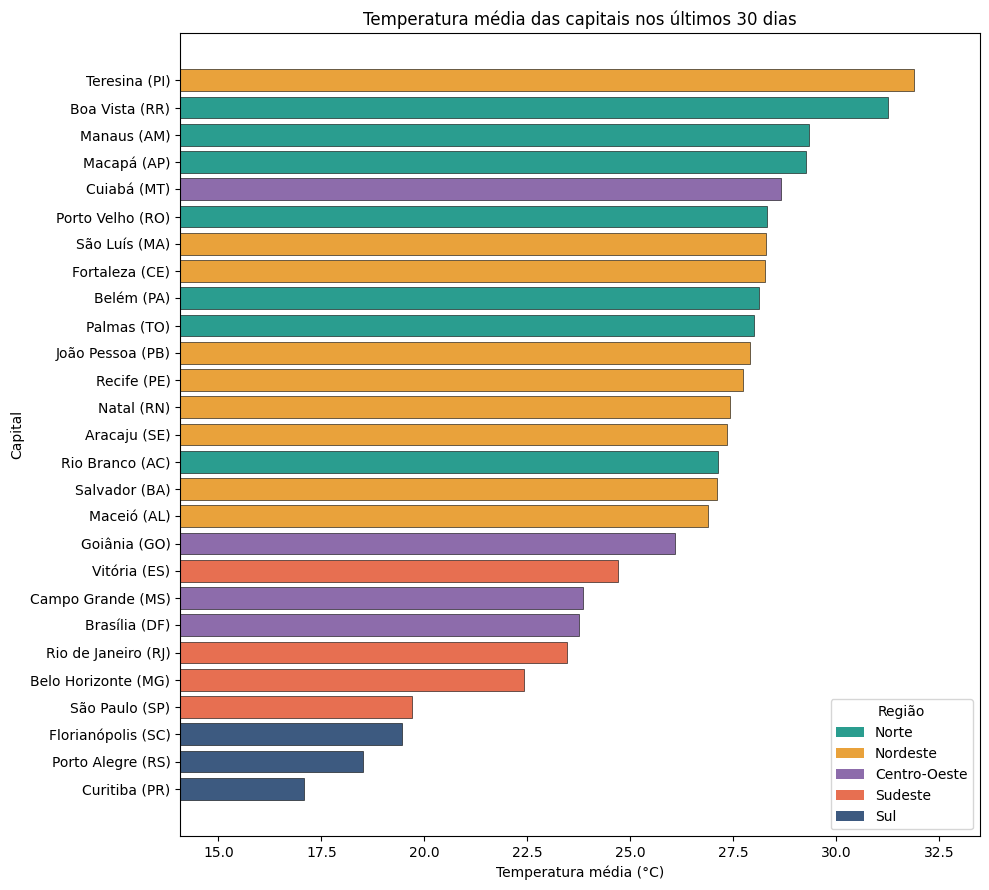

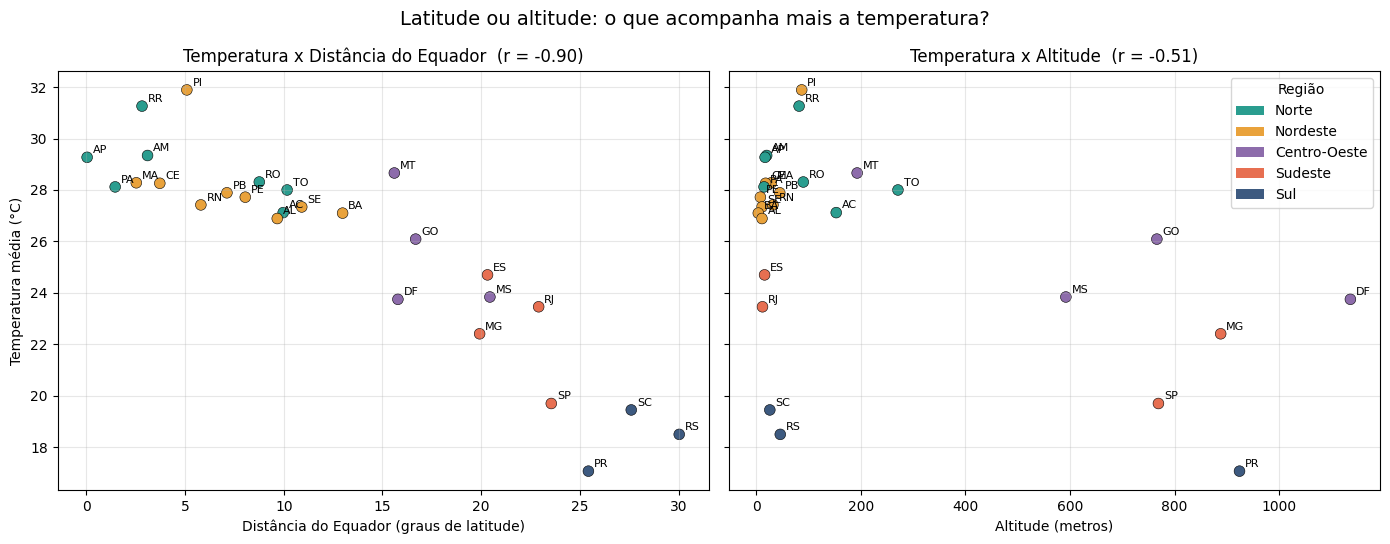

In [ ]:
# ============================================================
# PARTE 9: VISUALIZAÇÃO
# ============================================================
CORES_REGIAO = {"Norte": "#2a9d8f", "Nordeste": "#e9a23b", "Centro-Oeste": "#8d6cab",
                "Sudeste": "#e76f51", "Sul": "#3d5a80"}
cores = df_final["regiao"].map(CORES_REGIAO).fillna("gray")

# --- Gráfico 1: ranking de temperatura média ---
ordenado = df_final.sort_values("temp_media_c")
plt.figure(figsize=(10, 9))
plt.barh(ordenado["capital"] + " (" + ordenado["uf"] + ")", ordenado["temp_media_c"],
         color=ordenado["regiao"].map(CORES_REGIAO), edgecolor="black", linewidth=0.4)
legenda = [Patch(facecolor=cor, label=regiao) for regiao, cor in CORES_REGIAO.items()]
plt.legend(handles=legenda, title="Região", loc="lower right")
plt.title(f"Temperatura média das capitais nos últimos {DIAS_HISTORICO} dias")
plt.xlabel("Temperatura média (°C)")
plt.ylabel("Capital")
plt.xlim(left=max(0, ordenado["temp_media_c"].min() - 3))
plt.tight_layout()
plt.savefig(os.path.join(PASTA_GRAFICOS, "ranking_temperatura.png"), dpi=150)
plt.show()

# --- Gráfico 2: latitude x altitude, qual explica mais? ---
fig, eixos = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)
comparacoes = [
    ("dist_equador_graus", "Distância do Equador (graus de latitude)", corr_latitude),
    ("altitude_m", "Altitude (metros)", corr_altitude),
]
for eixo, (coluna, rotulo, r) in zip(eixos, comparacoes):
    eixo.scatter(df_final[coluna], df_final["temp_media_c"], c=cores, s=60, edgecolor="black", linewidth=0.4)
    for _, cap in df_final.iterrows():
        eixo.annotate(cap["uf"], (cap[coluna], cap["temp_media_c"]),
                      xytext=(4, 3), textcoords="offset points", fontsize=8)
    eixo.set_title(f"Temperatura x {rotulo.split(' (')[0]}  (r = {r:+.2f})")
    eixo.set_xlabel(rotulo)
    eixo.grid(alpha=0.3)
eixos[0].set_ylabel("Temperatura média (°C)")
eixos[1].legend(handles=legenda, title="Região", loc="upper right")
fig.suptitle("Latitude ou altitude: o que acompanha mais a temperatura?", fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(PASTA_GRAFICOS, "latitude_vs_altitude.png"), dpi=150)
plt.show()

In [ ]:
# ============================================================
# PARTE 10: SALVAMENTO E DOCUMENTAÇÃO
# ============================================================
ARQ_FINAL = "dataset_clima_capitais.csv"
ARQ_DIARIO = "dataset_clima_diario.csv"
df_final.to_csv(ARQ_FINAL, index=False, encoding="utf-8")
df_diario.to_csv(ARQ_DIARIO, index=False, encoding="utf-8")


def intensidade(r):
    """Traduz o número da correlação em palavras."""
    forca = "forte" if abs(r) >= 0.7 else "moderada" if abs(r) >= 0.4 else "fraca"
    sentido = "negativa" if r < 0 else "positiva"
    return f"{forca} e {sentido} (r = {r:+.2f})"


quente = df_final.iloc[0]
fria = df_final.iloc[-1]
chuvosa = df_final.loc[df_final["chuva_total_mm"].idxmax()]
amplitude = df_final.loc[df_final["amplitude_termica_c"].idxmax()]
regiao_quente = por_regiao.index[0]
fator = "a altitude" if abs(corr_altitude) > abs(corr_latitude) else "a distância do Equador"

insights = [
    f"A capital mais quente no período foi {quente['capital']}-{quente['uf']} "
    f"({quente['temp_media_c']:.1f} °C) e a mais fria foi {fria['capital']}-{fria['uf']} "
    f"({fria['temp_media_c']:.1f} °C): diferença de {quente['temp_media_c'] - fria['temp_media_c']:.1f} °C.",
    f"A região com maior temperatura média foi a {regiao_quente} "
    f"({por_regiao.loc[regiao_quente, 'temp_media_c']:.1f} °C).",
    f"A correlação entre altitude e temperatura foi {intensidade(corr_altitude)}; "
    f"entre distância do Equador e temperatura foi {intensidade(corr_latitude)}. "
    f"Neste período, {fator} acompanhou melhor a variação de temperatura.",
    f"{chuvosa['capital']}-{chuvosa['uf']} foi a capital mais chuvosa "
    f"({chuvosa['chuva_total_mm']:.0f} mm em {int(chuvosa['dias_observados'])} dias).",
    f"A maior amplitude térmica (diferença média entre máxima e mínima) foi em "
    f"{amplitude['capital']}-{amplitude['uf']}: {amplitude['amplitude_termica_c']:.1f} °C.",
]

dicionario = {
    "uf": "Sigla da unidade da federação (IBGE)",
    "estado": "Nome do estado (IBGE)",
    "regiao": "Região geográfica (IBGE)",
    "capital": "Nome da capital",
    "latitude / longitude": "Coordenadas da cidade em graus (Open-Meteo Geocoding)",
    "dist_equador_graus": "Distância do Equador = valor absoluto da latitude (calculada)",
    "altitude_m": "Altitude da cidade em metros (Open-Meteo Geocoding)",
    "populacao": "População informada pelo Geocoding (GeoNames); pode estar desatualizada",
    "temp_media_c": "Média das temperaturas médias diárias no período (°C)",
    "temp_max_media_c / temp_min_media_c": "Média das máximas / mínimas diárias (°C)",
    "amplitude_termica_c": "temp_max_media_c - temp_min_media_c (°C)",
    "chuva_total_mm": "Chuva acumulada no período (mm)",
    "dias_com_chuva": "Dias com 1 mm de chuva ou mais",
    "umidade_media_pct": "Umidade relativa média (%)",
    "dias_observados": "Quantidade de dias válidos após a limpeza",
    "periodo_inicio / periodo_fim": "Primeiro e último dia analisados",
    "data_coleta": "Data em que o notebook foi executado",
}

tamanho_kb = os.path.getsize(ARQ_FINAL) / 1024
doc = f"""# Projeto de Coleta: Clima nas 27 capitais brasileiras
**Autora:** Ingrid Cutrim | **Disciplina:** D1INT, Introdução à Ciência de Dados
**Data da coleta:** {DATA_COLETA.strftime('%d/%m/%Y %H:%M')}
**Período dos dados:** {df_final['periodo_inicio'].min()} a {df_final['periodo_fim'].max()}

## Pergunta
O que acompanha mais a temperatura média das capitais: a latitude ou a altitude?

## Fontes (todas via API REST, sem chave)
| Fonte | URL | Dados |
|---|---|---|
| IBGE Localidades | {FONTE_ESTADOS} | estado e região |
| Open-Meteo Geocoding | {URL_GEO} | coordenadas, altitude, população |
| Open-Meteo Forecast | {URL_CLIMA} | temperatura, chuva e umidade diárias |

## Arquivos gerados
- `{ARQ_FINAL}`: {len(df_final)} linhas x {df_final.shape[1]} colunas ({tamanho_kb:.1f} KB), uma linha por capital
- `{ARQ_DIARIO}`: {len(df_diario)} registros diários limpos
- `{PASTA_BRUTOS}/`: respostas originais das APIs (JSON)
- `{PASTA_GRAFICOS}/`: gráficos em PNG

## Limpeza aplicada
Conversão de tipos (to_datetime / to_numeric), remoção do dia atual (incompleto), remoção de
duplicatas por capital+dia, remoção de dias sem temperatura, chuva ausente = 0 mm, filtros de
consistência (-10 a 50 °C, máxima >= mínima, chuva >= 0).

## Dicionário de dados
| Coluna | Descrição |
|---|---|
""" + "\n".join(f"| {k} | {v} |" for k, v in dicionario.items()) + """

## Insights
""" + "\n".join(f"{n}. {t}" for n, t in enumerate(insights, start=1)) + """

## Limitações
- São só 30 dias: o resultado reflete a estação atual, não o clima do ano todo.
- Os dados diários vêm de modelos meteorológicos (Open-Meteo), não diretamente de estações.
- Uma coordenada representa a cidade inteira; bairros podem ter clima diferente.
- Correlação não prova causa; latitude e altitude também se misturam com distância do mar.
"""

with open("documentacao.md", "w", encoding="utf-8") as f:
    f.write(doc)

print("✅ Arquivos salvos:")
for arquivo in [ARQ_FINAL, ARQ_DIARIO, "documentacao.md"]:
    print(f"   {arquivo}  ({os.path.getsize(arquivo) / 1024:.1f} KB)")
print("\n💡 INSIGHTS:")
for n, texto in enumerate(insights, start=1):
    print(f"{n}. {texto}")

✅ Arquivos salvos:
   dataset_clima_capitais.csv  (3.8 KB)
   dataset_clima_diario.csv  (36.5 KB)
   documentacao.md  (3.3 KB)

💡 INSIGHTS:
1. A capital mais quente no período foi Teresina-PI (31.9 °C) e a mais fria foi Curitiba-PR (17.1 °C): diferença de 14.8 °C.
2. A região com maior temperatura média foi a Norte (28.8 °C).
3. A correlação entre altitude e temperatura foi moderada e negativa (r = -0.51); entre distância do Equador e temperatura foi forte e negativa (r = -0.90). Neste período, a distância do Equador acompanhou melhor a variação de temperatura.
4. Rio Branco-AC foi a capital mais chuvosa (251 mm em 30 dias).
5. A maior amplitude térmica (diferença média entre máxima e mínima) foi em Teresina-PI: 13.3 °C.


---
# PROJETO DE COLETA DE DADOS
## Clima nas 27 capitais brasileiras: latitude ou altitude?

**Autora:** Ingrid Cutrim
**Data:** [data da coleta, aparece na saída da Parte 1]
**Disciplina:** Introdução à Ciência de Dados

---

## 1. OBJETIVO
Montar um dataset próprio com o clima recente das 27 capitais brasileiras, combinando três fontes públicas,
para verificar se a temperatura média acompanha mais a latitude (distância do Equador) ou a altitude da cidade.

## 2. FONTES DE DADOS
| Fonte | URL | Método | Dados Coletados |
|-------|-----|--------|-----------------|
| IBGE Localidades (ou BrasilAPI, como plano B) | https://servicodados.ibge.gov.br/api/v1/localidades/estados · https://brasilapi.com.br/api/ibge/uf/v1 | API | Sigla, nome do estado e região |
| Open-Meteo Geocoding | https://geocoding-api.open-meteo.com/v1/search | API | Latitude, longitude, altitude, população |
| Open-Meteo Forecast | https://api.open-meteo.com/v1/forecast | API | Temperatura máx./mín./média, chuva e umidade diárias (30 dias) |

## 3. METODOLOGIA
### 3.1 Coleta
Três APIs REST consumidas com `requests`. Uma função (`buscar_json`) concentra o tratamento de erros:
`try/except`, até 3 tentativas, espera extra no erro 429 e `timeout`. Há `time.sleep(1)` entre requisições
e um User-Agent identificando o projeto. Todas as respostas originais foram salvas em `dados_brutos/` antes da limpeza.

### 3.2 Limpeza
Conversão de tipos com `to_datetime` e `to_numeric(errors="coerce")`; remoção do dia atual (ainda incompleto);
`drop_duplicates` por capital + dia; `dropna` em dias sem temperatura; chuva ausente preenchida com 0;
filtros de consistência (temperatura entre -10 e 50 °C, máxima ≥ mínima, chuva ≥ 0).

### 3.3 Processamento
Agregação por capital com `groupby().agg()` (médias, soma de chuva, dias chuvosos), cálculo da amplitude térmica e da
distância do Equador, e união das três fontes com `merge` pelas chaves `uf` e `capital`.

## 4. DATASET FINAL
- **Total de registros:** Dataset final: 27 linhas x 20 colunas
- **Total de colunas:** 20
- **Período:** 2026-10-10 a 2026-11-08
- **Tamanho do arquivo:** dataset_clima_capitais.csv  (3.8 KB)
dataset_clima_diario.csv  (36.5 KB)
documentacao.md  (3.3 KB)

### Colunas:
| Coluna | Tipo | Descrição |
|--------|------|-----------|
| uf | texto | Sigla do estado |
| estado | texto | Nome do estado |
| regiao | texto | Região geográfica |
| capital | texto | Nome da capital |
| latitude / longitude | decimal | Coordenadas (graus) |
| dist_equador_graus | decimal | Valor absoluto da latitude |
| altitude_m | decimal | Altitude (m) |
| populacao | inteiro | População (GeoNames) |
| temp_media_c | decimal | Temperatura média do período (°C) |
| temp_max_media_c | decimal | Média das máximas (°C) |
| temp_min_media_c | decimal | Média das mínimas (°C) |
| amplitude_termica_c | decimal | Máxima média − mínima média (°C) |
| chuva_total_mm | decimal | Chuva acumulada (mm) |
| dias_com_chuva | inteiro | Dias com ≥ 1 mm |
| umidade_media_pct | decimal | Umidade relativa média (%) |
| dias_observados | inteiro | Dias válidos após a limpeza |
| periodo_inicio / periodo_fim | data | Intervalo analisado |
| data_coleta | data | Dia da execução |

## 5. ANÁLISE EXPLORATÓRIA
### 5.1 Estatísticas Descritivas
Ver a tabela `describe()`, o top 5 quentes/frias e as médias por região na Parte 8.

### 5.2 Visualizações
Ranking de temperatura por capital (barras, cor por região) e dois gráficos de dispersão
(temperatura × distância do Equador e temperatura × altitude), na Parte 9 e na pasta `graficos/`.

## 6. INSIGHTS
1. A capital mais quente no período foi Teresina-PI (31.9 °C) e a mais fria foi Curitiba-PR (17.1 °C): diferença de 14.8 °C.
2. A região com maior temperatura média foi a Norte (28.8 °C).
3. A correlação entre altitude e temperatura foi moderada e negativa (r = -0.51); entre distância do Equador e temperatura foi forte e negativa (r = -0.90). Neste período, a distância do Equador acompanhou melhor a variação de temperatura.
4. Rio Branco-AC foi a capital mais chuvosa (251 mm em 30 dias).
5. A maior amplitude térmica (diferença média entre máxima e mínima) foi em Teresina-PI: 13.3 °C.

## 7. LIMITAÇÕES
- A API oficial do IBGE não respondeu a partir do Colab (servidor fora do Brasil), por isso o código tem plano B (BrasilAPI). A fonte usada aparece na saída da Parte 3.
- O período é de apenas 30 dias, então reflete a estação atual e não o clima anual.
- Os dados diários são de modelos meteorológicos, não de estações oficiais (INMET).
- Uma única coordenada representa a cidade inteira.
- Correlação não é causa: a proximidade do mar e a vegetação também influenciam.

## 8. PRÓXIMOS PASSOS
- Usar a Historical Weather API da Open-Meteo para comparar um ano inteiro (verão × inverno).
- Incluir a distância até o litoral como uma terceira variável.
- Fazer uma regressão com latitude e altitude juntas para separar o efeito de cada uma.

## 9. CÓDIGO
[link do repositório no GitHub] · [https://colab.research.google.com/drive/1bcbIPX-GvMo74Zg5YamJx2InM2uyMgdK#scrollTo=cell-12]

## 10. REFERÊNCIAS
- IBGE, API de Localidades: https://servicodados.ibge.gov.br/api/docs/localidades
- Open-Meteo, Weather Forecast API: https://open-meteo.com/en/docs
- Open-Meteo, Geocoding API: https://open-meteo.com/en/docs/geocoding-api
- Material das Aulas 4.1 e 4.2, Prof. Danilo Pereira

In [16]:
import shutil
from google.colab import files
shutil.make_archive("projeto_saida", "zip", ".", ".")
files.download("projeto_saida.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>